# 02 — Selección de la imagen Sentinel-2 por departamento

**Proyecto FORMAR 2024-2026 · GWCCI**

Para cada departamento y campaña se elige **una** adquisición Sentinel-2 sobre la que luego se calcula el GWCCI.

**Regla:** entre las adquisiciones fecha–órbita de enero–marzo con cobertura del área agrícola ≥ 95 %, se elige la de **mayor GCC medio** del área agrícola. Un control radiométrico con superficies urbanas (ESA WorldCover, clase 50) verifica que el máximo no sea un artefacto de la imagen.

| Sección | Qué hace | Salida |
|---|---|---|
| 1 | Configuración y funciones | — |
| 2 | Cobertura de cada órbita por departamento (se calcula una sola vez) | `cobertura_orbitas_departamentos.csv` |
| 3 | Serie de GCC por fecha–órbita, 95 departamentos (con caché) | `serie_gcc_95deptos_<campaña>.csv` |
| 4 | Control de la serie | — |
| 5 | Selección de la imagen + salto agrícola | `seleccion_imagen_<campaña>.csv` |
| 6 | Control radiométrico urbano | agrega `salto_urb`, `n_urb` |
| 7 | Diagnóstico de un departamento (opcional) | tabla por bandas y figura en color real |

Las secciones 2 y 3 guardan sus resultados: si el CSV ya existe, no recalculan. Las pruebas y alternativas descartadas están en `01_exploracion_ventana_gcc.ipynb`.

## 1. Configuración

In [2]:
import os, time, io, urllib.request
import ee
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ee.Initialize(project="ee-mnolasco")

# --- Parámetros -----------------------------------------------------------
CAMPANIA = 2021              # campaña 2020/2021 -> 2021
BASE = "users/mnolasco/FORMAR_2024_2026"
T = "../results/tables"
FIG = "../results/figures"

CS_UMBRAL = 0.60             # Cloud Score+ (cs_cdf): píxel válido si >=
ESCALA = 60                  # m, reducción de la serie
CRS = "EPSG:32720"
COB_MIN = 95                 # % de cobertura para que una fecha sea elegible
COB_PICO = 50                # % de cobertura para ubicar el pico de referencia
SERIE_DESDE = f"{CAMPANIA - 1}-11-01"
SERIE_HASTA = f"{CAMPANIA}-06-01"          # fin exclusivo
SEL_DESDE = f"{CAMPANIA}-01-01"
SEL_HASTA = f"{CAMPANIA}-04-01"            # fin exclusivo

# --- Assets ---------------------------------------------------------------
deptos = ee.FeatureCollection(f"{BASE}/departments_selected")
agricola = ee.Image(f"{BASE}/AgriLand-2019").eq(1).selfMask()
soja = agricola.updateMask(ee.Image(f"{BASE}/MNC_verano-{CAMPANIA}").eq(11))   # solo control
urbano = ee.ImageCollection("ESA/WorldCover/v200").first().eq(50).selfMask()
cs = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")
s2_base = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
RED = ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True)

# --- Funciones ------------------------------------------------------------
def coleccion_dia(fecha, orbita, region, con_cs=True):
    """Gránulos de una fecha y órbita, con B2-B4 en reflectancia (y máscara Cloud Score+)."""
    col = (s2_base.filterDate(fecha, ee.Date(fecha).advance(1, "day"))
           .filter(ee.Filter.eq("SENSING_ORBIT_NUMBER", int(orbita)))
           .filterBounds(region))
    if con_cs:
        col = col.linkCollection(cs, ["cs_cdf"])
        return col.map(lambda i: i.select(["B2", "B3", "B4"]).divide(10000).toFloat()
                                  .updateMask(i.select("cs_cdf").gte(CS_UMBRAL)))
    return col.map(lambda i: i.select(["B2", "B3", "B4"]).divide(10000).toFloat())

def con_gcc(img):
    """Agrega la banda gcc = G / (B + G + R)."""
    g = img.select("B3").divide(img.select("B2").add(img.select("B3")).add(img.select("B4")))
    return img.addBands(g.rename("gcc"))

def get_info(obj, etiqueta, intentos=3, espera=15):
    """getInfo con reintentos; devuelve None si falla siempre."""
    for k in range(intentos):
        try:
            return obj.getInfo()
        except Exception as e:
            print(f"  {etiqueta}: error ({str(e)[:80]}); reintento {k + 1}/{intentos}")
            time.sleep(espera)
    return None

print("Configuración lista — campaña", CAMPANIA)

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Configuración lista — campaña 2021


## 2. Cobertura de cada órbita por departamento

Huella de cada órbita relativa (unión de sus fechas, sin máscara de nubes) y porcentaje del área agrícola de cada departamento que cubre. La geometría de las órbitas no cambia entre campañas: se calcula una sola vez.

In [2]:
RUTA_ORB = f"{T}/cobertura_orbitas_departamentos.csv"

if os.path.exists(RUTA_ORB):
    tabla_orb = pd.read_csv(RUTA_ORB, dtype={"link": str}).set_index(["link", "departamento", "provincia"])
    orbitas = [c for c in tabla_orb.columns if c.isdigit()]
    print("Leída de", RUTA_ORB)
else:
    s2_orb = s2_base.filterBounds(deptos).filterDate(f"{CAMPANIA}-01-01", f"{CAMPANIA}-03-01")
    orbitas = sorted(s2_orb.aggregate_array("SENSING_ORBIT_NUMBER").distinct().getInfo())
    filas = []
    for o in orbitas:
        huella = (s2_orb.filter(ee.Filter.eq("SENSING_ORBIT_NUMBER", o))
                  .map(lambda i: i.select("B2").mask().rename("h")).max())
        img = ee.Image.cat(agricola.rename("total"), agricola.updateMask(huella).rename("cubierta"))
        res = get_info(img.reduceRegions(collection=deptos.select(["link", "departamen", "provincia"]),
                                         reducer=ee.Reducer.count(), crs=CRS, scale=100, tileScale=4),
                       f"órbita {o}")
        for f in res["features"]:
            p = f["properties"]
            filas.append({"link": str(p["link"]).zfill(5), "departamento": p["departamen"],
                          "provincia": p["provincia"], "orbita": o,
                          "total": p.get("total", 0), "cubierta": p.get("cubierta", 0)})
        print(f"órbita {o}: listo")
    o_df = pd.DataFrame(filas)
    o_df["pct"] = 100 * o_df["cubierta"] / o_df["total"]
    tabla_orb = o_df.pivot_table(index=["link", "departamento", "provincia"],
                                 columns="orbita", values="pct").round(1)
    tabla_orb.columns = [str(c) for c in tabla_orb.columns]
    orbitas = list(tabla_orb.columns)
    tabla_orb["max_pct"] = tabla_orb[orbitas].max(axis=1)
    tabla_orb["n_orbitas"] = (tabla_orb[orbitas] > 1).sum(axis=1)
    tabla_orb.to_csv(RUTA_ORB)

print("Órbitas relativas:", orbitas)
print(f"Cubiertos completos (≥ 99 %) por al menos una órbita: {(tabla_orb['max_pct'] >= 99).sum()} de {len(tabla_orb)}")
print("Departamentos según cuántas órbitas los tocan:")
print(tabla_orb["n_orbitas"].value_counts().sort_index().to_string())
print("\nControl — 25 de Mayo (esperado: una órbita ~100 %, otra ~76 %):")
print(tabla_orb.xs("06854", level="link").to_string())

Leída de ../results/tables/cobertura_orbitas_departamentos.csv
Órbitas relativas: ['10', '24', '67', '110', '124']
Cubiertos completos (≥ 99 %) por al menos una órbita: 95 de 95
Departamentos según cuántas órbitas los tocan:
n_orbitas
1    39
2    56

Control — 25 de Mayo (esperado: una órbita ~100 %, otra ~76 %):
                            10     24    67  110  124  max_pct  n_orbitas
departamento provincia                                                   
25 de Mayo   Buenos Aires  0.0  100.0  75.9  0.0  0.0    100.0          2


## 3. Serie de GCC por fecha–órbita (95 departamentos)

Por cada fecha–órbita de noviembre a mayo: mosaico de los gránulos, máscara Cloud Score+, GCC medio del área agrícola (y de la soja INTA, solo como control) y conteo de píxeles agrícolas totales y válidos, en la misma grilla. Guarda cada fecha a medida que avanza: si se corta, al volver a correr sigue donde quedó. Para recalcular desde cero hay que borrar el CSV.

`PRUEBA = 3` calcula solo 3 fechas (para medir tiempos); `None`, todas. ~40 s por fecha–órbita.

In [3]:
RUTA_SERIE = f"{T}/serie_gcc_95deptos_{CAMPANIA}.csv"
PRUEBA = None

d_link = deptos.select(["link"])
s2_clave = (s2_base.filterBounds(deptos).filterDate(SERIE_DESDE, SERIE_HASTA)
            .map(lambda i: i.set("clave",
                 ee.Date(i.get("system:time_start")).format("YYYY-MM-dd").cat("_")
                   .cat(ee.Number(i.get("SENSING_ORBIT_NUMBER")).toInt().format("%d")))))
claves = sorted(s2_clave.aggregate_array("clave").distinct().getInfo())
hechas = set(pd.read_csv(RUTA_SERIE)["clave"]) if os.path.exists(RUTA_SERIE) else set()
pendientes = [c for c in claves if c not in hechas]
lista = pendientes[:PRUEBA] if PRUEBA else pendientes
print(f"{len(claves)} fecha-órbita en total; faltan {len(pendientes)}")

for n, c in enumerate(lista, 1):
    t0 = time.time()
    fecha, orb = c[:10], int(c[11:])
    col = coleccion_dia(fecha, orb, deptos)
    g = con_gcc(col.mosaic()).select("gcc")
    img = ee.Image.cat(agricola.rename("total"),
                       g.updateMask(agricola).rename("agr"),
                       g.updateMask(soja).rename("soja"))
    res = get_info(img.reduceRegions(collection=d_link.filterBounds(col.geometry()),
                                     reducer=RED, crs=CRS, scale=ESCALA, tileScale=4), c)
    if res is None:
        continue
    filas = []
    for f in res["features"]:
        p = f["properties"]
        if not p.get("total_count"):
            continue
        filas.append({"clave": c, "fecha": fecha, "orbita": orb, "link": str(p["link"]).zfill(5),
                      "gcc_agr": p.get("agr_mean"), "gcc_soja": p.get("soja_mean"),
                      "total": p["total_count"], "validos": p.get("agr_count", 0)})
    if filas:
        pd.DataFrame(filas).to_csv(RUTA_SERIE, mode="a", header=not os.path.exists(RUTA_SERIE), index=False)
    print(f"[{n}/{len(lista)}] {c}: {len(filas)} deptos, {time.time() - t0:.0f} s")

print(f"Pendientes: {len(pendientes) - len(lista)}")

211 fecha-órbita en total; faltan 0
Pendientes: 0


## 4. Control de la serie

In [4]:
df = pd.read_csv(RUTA_SERIE, dtype={"link": str}, parse_dates=["fecha"])
df["cobertura"] = 100 * df["validos"] / df["total"]

print(df["clave"].nunique(), "fecha-órbita;", len(df), "filas;", df["link"].nunique(), "departamentos")
print("Filas duplicadas (clave, link):", df.duplicated(["clave", "link"]).sum())
print("Cobertura máxima:", round(df["cobertura"].max(), 2), "%  (debe ser ≤ 100)")

em = df[(df["fecha"] >= SEL_DESDE) & (df["fecha"] < SEL_HASTA)]
n_fechas = pd.DataFrame({
    "fechas_ene_mar": em.groupby("link").size(),
    f"con_{COB_MIN}": em[em["cobertura"] >= COB_MIN].groupby("link").size(),
}).reindex(sorted(df["link"].unique())).fillna(0).astype(int)

print(f"\nFechas-órbita por departamento en el período de selección:")
print(n_fechas.describe().round(1).to_string())
print(f"\nDepartamentos sin ninguna fecha ≥ {COB_MIN} %:", (n_fechas[f"con_{COB_MIN}"] == 0).sum())

211 fecha-órbita; 6697 filas; 95 departamentos
Filas duplicadas (clave, link): 0
Cobertura máxima: 100.0 %  (debe ser ≤ 100)

Fechas-órbita por departamento en el período de selección:
       fechas_ene_mar  con_95
count            95.0    95.0
mean             29.9     7.5
std               8.4     2.5
min              18.0     4.0
25%              18.0     6.0
50%              36.0     7.0
75%              36.0     8.0
max              36.0    16.0

Departamentos sin ninguna fecha ≥ 95 %: 0


## 5. Selección de la imagen

Para cada departamento:

* **Imagen elegida:** máximo GCC agrícola entre las fechas del período con cobertura ≥ `COB_MIN`.
* **Pico de referencia:** máximo GCC del período con cobertura ≥ `COB_PICO` (para medir la distancia).
* **Base:** mínimo GCC de la campaña (fechas ≥ `COB_MIN`), para el porcentaje de recorrido.
* **Salto agrícola:** GCC elegido menos el promedio de la fecha válida anterior y la posterior. Las vecinas se guardan para el control urbano.

In [5]:
cob = tabla_orb.reset_index()[["link", "departamento", "provincia"]]

def seleccionar(g):
    v = g[g["cobertura"] >= COB_MIN].sort_values("fecha").reset_index(drop=True)
    em = g[(g["fecha"] >= SEL_DESDE) & (g["fecha"] < SEL_HASTA)]
    ref = em[em["cobertura"] >= COB_PICO]
    pico = ref.loc[ref["gcc_agr"].idxmax()]
    cand = v[(v["fecha"] >= SEL_DESDE) & (v["fecha"] < SEL_HASTA)]
    i = cand["gcc_agr"].idxmax()                    # índice dentro de v
    s = v.loc[i]
    base = v["gcc_agr"].min()
    ant = v.loc[i - 1] if i > 0 else None
    post = v.loc[i + 1] if i + 1 < len(v) else None
    vecinas = [x["gcc_agr"] for x in (ant, post) if x is not None]
    return pd.Series({
        "fecha_sel": s["fecha"], "doy_sel": s["fecha"].dayofyear, "orbita_sel": int(s["orbita"]),
        "cob_sel": round(s["cobertura"], 1), "gcc_sel": round(s["gcc_agr"], 4),
        "gcc_soja_sel": round(s["gcc_soja"], 4),
        "fecha_pico": pico["fecha"], "cob_pico": round(pico["cobertura"], 1),
        "gcc_pico": round(pico["gcc_agr"], 4),
        "dias_al_pico": abs((s["fecha"] - pico["fecha"]).days),
        "gcc_base": round(base, 4),
        "pct_recorrido": round(100 * (s["gcc_agr"] - base) / (pico["gcc_agr"] - base), 1),
        "salto": round(s["gcc_agr"] - sum(vecinas) / len(vecinas), 4),
        "fecha_ant": ant["fecha"] if ant is not None else pd.NaT,
        "orbita_ant": int(ant["orbita"]) if ant is not None else None,
        "fecha_post": post["fecha"] if post is not None else pd.NaT,
        "orbita_post": int(post["orbita"]) if post is not None else None,
    })

sel = pd.DataFrame([seleccionar(g).rename(l) for l, g in df.groupby("link")])
sel = sel.rename_axis("link").reset_index().merge(cob, on="link", how="left")
RUTA_SEL = f"{T}/seleccion_imagen_{CAMPANIA}.csv"
sel.to_csv(RUTA_SEL, index=False)

print("Fechas elegidas más frecuentes:")
print(sel["fecha_sel"].dt.date.value_counts().head(8).to_string())
print("\nDía del año elegido, por provincia:")
print(sel.groupby("provincia")["doy_sel"].describe()[["count", "min", "50%", "max"]].to_string())
print("\nDías al pico:", sel["dias_al_pico"].describe()[["50%", "75%", "max"]].to_dict())
print("% del recorrido:", sel["pct_recorrido"].describe()[["min", "25%", "50%"]].to_dict())
print("Salto agrícola:", sel["salto"].astype(float).describe()[["mean", "min", "max"]].round(4).to_dict())

Fechas elegidas más frecuentes:
fecha_sel
2021-02-05    44
2021-02-18    14
2021-02-17    13
2021-02-22     7
2021-02-07     4
2021-03-30     4
2021-02-24     2
2021-02-15     2

Día del año elegido, por provincia:
              count   min   50%   max
provincia                            
Buenos Aires   56.0  20.0  36.0  58.0
Córdoba        14.0  36.0  49.0  89.0
Entre Ríos      8.0  36.0  37.0  48.0
La Pampa        5.0  49.0  49.0  89.0
Santa Fe       12.0  36.0  36.0  36.0

Días al pico: {'50%': 0.0, '75%': 3.5, 'max': 35.0}
% del recorrido: {'min': 73.8, '25%': 99.15, '50%': 100.0}
Salto agrícola: {'mean': 0.0333, 'min': 0.0071, 'max': 0.0749}


## 6. Control radiométrico urbano

GCC medio de la superficie edificada (ESA WorldCover 2021, clase 50) en la fecha elegida y en sus dos vecinas. **Salto urbano** = elegida − promedio de las vecinas. Si es cercano a cero, el salto agrícola corresponde a la vegetación; si es comparable al agrícola, la fecha es sospechosa. Los pedidos se agrupan por fecha–órbita (~1 min cada una).

In [6]:
pedidos = []
for _, s in sel.iterrows():
    for rol, f, o in [("anterior", s["fecha_ant"], s["orbita_ant"]),
                      ("elegida", s["fecha_sel"], s["orbita_sel"]),
                      ("posterior", s["fecha_post"], s["orbita_post"])]:
        if pd.notna(f):
            pedidos.append({"link": s["link"], "rol": rol, "fecha": pd.Timestamp(f), "orbita": int(o)})
ped = pd.DataFrame(pedidos)
claves_u = ped[["fecha", "orbita"]].drop_duplicates().reset_index(drop=True)
print(len(ped), "pedidos;", len(claves_u), "fecha-órbita distintas")

d_link = deptos.select(["link"])
filas = []
for n, k in claves_u.iterrows():
    t0 = time.time()
    f = k["fecha"].strftime("%Y-%m-%d")
    links = ped[(ped["fecha"] == k["fecha"]) & (ped["orbita"] == k["orbita"])]["link"].unique().tolist()
    fc = d_link.filter(ee.Filter.inList("link", links))
    u = con_gcc(coleccion_dia(f, k["orbita"], fc).mosaic()).updateMask(urbano)
    res = get_info(u.reduceRegions(fc, RED, scale=30, crs=CRS, tileScale=4), f)
    if res is None:
        continue
    for feat in res["features"]:
        p = feat["properties"]
        filas.append({"link": p["link"], "fecha": k["fecha"], "orbita": int(k["orbita"]),
                      "gcc_urb": p.get("gcc_mean"), "n_urb": p.get("gcc_count", 0)})
    print(f"[{n + 1}/{len(claves_u)}] {f} órbita {int(k['orbita'])}: {len(links)} deptos, {time.time() - t0:.0f} s")

urb = ped.merge(pd.DataFrame(filas), on=["link", "fecha", "orbita"], how="left")
tab = urb.pivot_table(index="link", columns="rol", values="gcc_urb")
sel = sel.set_index("link")
sel["salto_urb"] = (tab["elegida"] - tab[["anterior", "posterior"]].mean(axis=1)).round(4)
sel["n_urb"] = urb[urb["rol"] == "elegida"].set_index("link")["n_urb"]
sel = sel.reset_index()
sel.to_csv(RUTA_SEL, index=False)

print("\nControl — Rosario (2021: salto ≈ 0.075, salto urbano ≈ 0.007):")
print(sel.loc[sel["link"] == "82084", ["departamento", "fecha_sel", "salto", "salto_urb", "n_urb"]].to_string(index=False))
print("\nSalto urbano:", sel["salto_urb"].describe()[["mean", "min", "max"]].round(4).to_dict())
print("Departamentos con menos de 1000 píxeles urbanos:", (sel["n_urb"] < 1000).sum())
print("\nLos 10 con mayor salto urbano:")
print(sel.reindex(sel["salto_urb"].abs().sort_values(ascending=False).index)
      [["link", "departamento", "provincia", "fecha_sel", "salto", "salto_urb", "n_urb"]]
      .head(10).to_string(index=False))

285 pedidos; 33 fecha-órbita distintas
[1/33] 2021-01-23 órbita 24: 8 deptos, 31 s
[2/33] 2021-02-17 órbita 24: 20 deptos, 62 s
[3/33] 2021-02-22 órbita 24: 9 deptos, 28 s
[4/33] 2021-02-05 órbita 67: 45 deptos, 175 s
[5/33] 2021-02-07 órbita 24: 20 deptos, 74 s
[6/33] 2021-03-09 órbita 24: 14 deptos, 30 s
[7/33] 2021-02-04 órbita 124: 3 deptos, 10 s
[8/33] 2021-02-24 órbita 124: 3 deptos, 8 s
[9/33] 2021-03-06 órbita 124: 1 deptos, 6 s
[10/33] 2021-01-31 órbita 67: 5 deptos, 18 s
[11/33] 2021-02-20 órbita 67: 35 deptos, 115 s
[12/33] 2021-01-21 órbita 67: 34 deptos, 147 s
[13/33] 2021-02-25 órbita 67: 3 deptos, 21 s
[14/33] 2021-02-27 órbita 24: 7 deptos, 25 s
[15/33] 2021-04-15 órbita 124: 1 deptos, 4 s
[16/33] 2021-01-26 órbita 67: 2 deptos, 7 s
[17/33] 2021-01-10 órbita 124: 1 deptos, 17 s
[18/33] 2021-01-20 órbita 124: 1 deptos, 3 s
[19/33] 2021-01-25 órbita 124: 1 deptos, 11 s
[20/33] 2021-02-18 órbita 110: 17 deptos, 93 s
[21/33] 2021-02-23 órbita 110: 9 deptos, 94 s
[22/33] 202

## 7. Diagnóstico de un departamento (opcional)

Para revisar un caso: bandas y GCC por zona (agrícola, no agrícola, urbana) en la fecha elegida y sus vecinas, y las tres imágenes en color real con el **mismo estiramiento** y **sin máscara de nubes**. Cambiar `LINK`.

Rosario (Santa Fe)
                gcc                           B2                           B3                           B4                    
zona       agrícola no agrícola  urbana agrícola no agrícola  urbana agrícola no agrícola  urbana agrícola no agrícola  urbana
fecha                                                                                                                         
2021-01-21   0.4084      0.3794  0.3467   0.0475      0.0756  0.1330   0.0743      0.1041  0.1572   0.0682      0.1046  0.1678
2021-02-05   0.5004      0.4072  0.3537   0.0255      0.0593  0.1175   0.0548      0.0900  0.1438   0.0352      0.0861  0.1518
2021-02-20   0.4431      0.3785  0.3457   0.0322      0.0674  0.1199   0.0534      0.0931  0.1420   0.0412      0.0951  0.1527


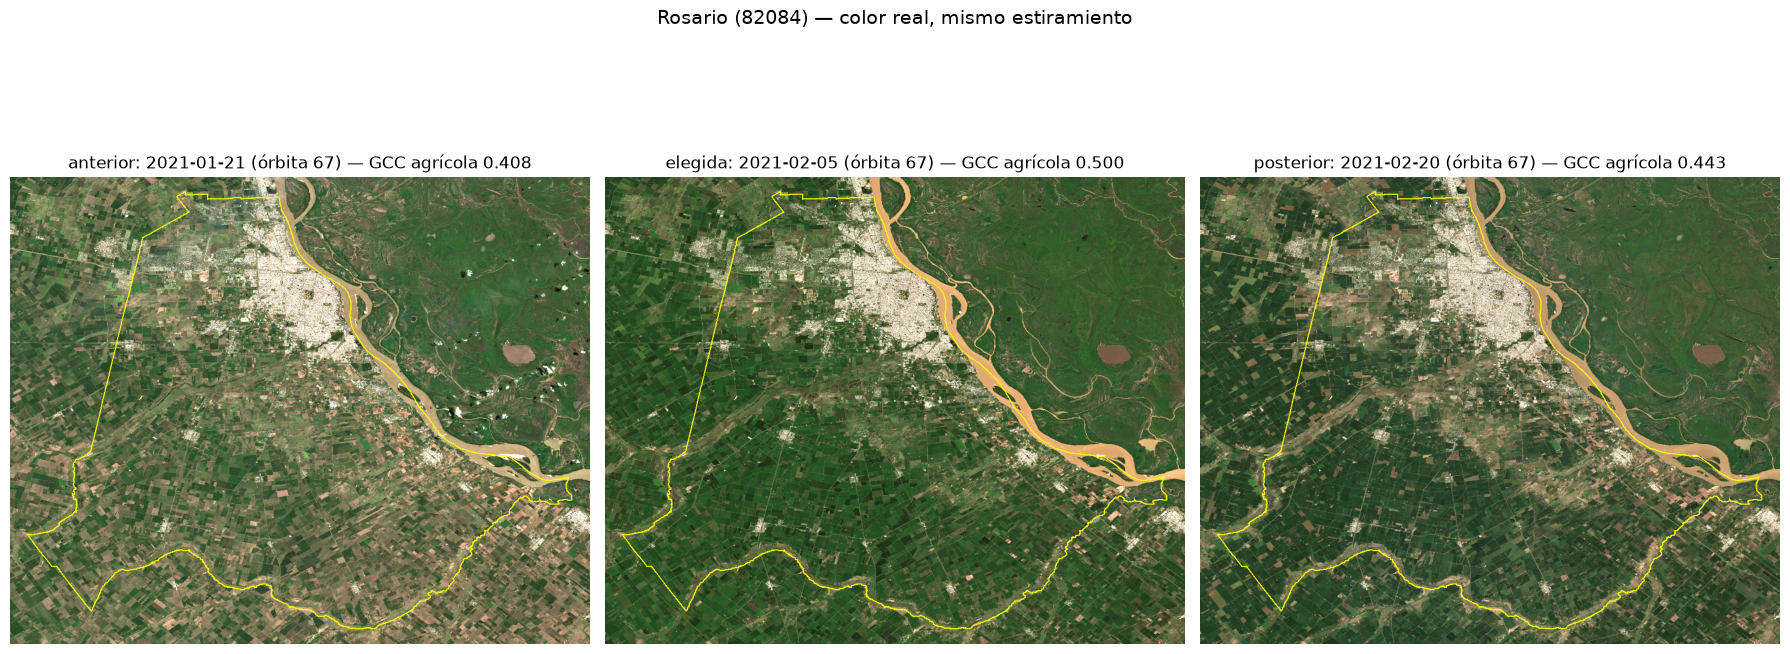

In [7]:
LINK = "82084"   # Rosario

s = sel.set_index("link").loc[LINK]
casos = [(r, s[f"fecha_{k}"], s[f"orbita_{k}"]) for r, k in
         [("anterior", "ant"), ("elegida", "sel"), ("posterior", "post")] if pd.notna(s[f"fecha_{k}"])]
geom = deptos.filter(ee.Filter.eq("link", LINK)).geometry()
agr01 = ee.Image(f"{BASE}/AgriLand-2019").eq(1).unmask(0)

filas = []
for rol, f, o in casos:
    f = pd.Timestamp(f).strftime("%Y-%m-%d")
    img = con_gcc(coleccion_dia(f, o, geom).mosaic())
    for zona, m in [("agrícola", agr01.eq(1)), ("no agrícola", agr01.eq(0)), ("urbana", urbano)]:
        r = img.updateMask(m).reduceRegion(ee.Reducer.mean(), geom, scale=ESCALA, crs=CRS,
                                           maxPixels=1e13, tileScale=4).getInfo()
        filas.append({"fecha": f, "zona": zona, **{b: round(r[b], 4) for b in ["B2", "B3", "B4", "gcc"]}})
diag = pd.DataFrame(filas)
print(f"{s['departamento']} ({s['provincia']})")
print(diag.pivot(index="fecha", columns="zona", values=["gcc", "B2", "B3", "B4"]).to_string())

VIS = {"bands": ["B4", "B3", "B2"], "min": 0, "max": 0.20, "gamma": 1.2}
borde = ee.Image().byte().paint(ee.FeatureCollection([ee.Feature(geom)]), 1, 2).visualize(palette=["ffff00"])
region = geom.bounds().buffer(2000)
fig, axes = plt.subplots(1, len(casos), figsize=(6 * len(casos), 8))
for ax, (rol, f, o) in zip(axes, casos):
    f = pd.Timestamp(f).strftime("%Y-%m-%d")
    img = coleccion_dia(f, o, geom, con_cs=False).mosaic()
    url = img.visualize(**VIS).blend(borde).getThumbURL({"region": region, "dimensions": 1024, "format": "png"})
    ax.imshow(Image.open(io.BytesIO(urllib.request.urlopen(url).read())))
    g = diag[(diag["fecha"] == f) & (diag["zona"] == "agrícola")]["gcc"].iloc[0]
    ax.set_title(f"{rol}: {f} (órbita {int(o)}) — GCC agrícola {g:.3f}", fontsize=12)
    ax.axis("off")
fig.suptitle(f"{s['departamento']} ({LINK}) — color real, mismo estiramiento", fontsize=14)
fig.tight_layout()
fig.savefig(f"{FIG}/color_real_{LINK}_{CAMPANIA}.png", dpi=150)
plt.show()

In [8]:
UMBRAL = 0.17
PILOTO = [("Río Segundo", "Córdoba"), ("Rosario", "Santa Fe"), ("25 de Mayo", "Buenos Aires")]
ref = ee.Image(f"{BASE}/MNC_verano-{CAMPANIA}").eq(11).rename("ref")    # 1 soja, 0 otra clase

def gwcci_dia(fecha, orbita, region):
    col = (s2_base.filterDate(fecha, ee.Date(fecha).advance(1, "day"))
           .filter(ee.Filter.eq("SENSING_ORBIT_NUMBER", int(orbita)))
           .filterBounds(region).linkCollection(cs, ["cs_cdf"]))
    img = col.map(lambda i: i.select(["B4", "B8", "B11"]).divide(10000).toFloat()
                             .updateMask(i.select("cs_cdf").gte(CS_UMBRAL))).mosaic()
    return img.normalizedDifference(["B8", "B4"]).multiply(img.select("B11")).rename("gwcci")

def metricas(h):
    tn, fp, fn, tp = (h.get(k, 0) for k in ("0", "1", "2", "3"))
    n = tn + fp + fn + tp
    oa = (tp + tn) / n
    pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / n ** 2
    pa, ua = tp / (tp + fn), tp / (tp + fp)
    return {"OA": round(100 * oa, 1), "kappa": round((oa - pe) / (1 - pe), 3),
            "PA": round(100 * pa, 1), "UA": round(100 * ua, 1), "F1": round(200 * pa * ua / (pa + ua), 1),
            "soja_INTA_%": round(100 * (tp + fn) / n, 1), "soja_GWCCI_%": round(100 * (tp + fp) / n, 1)}

filas, dist = [], []
for nombre, prov in PILOTO:
    t0 = time.time()
    s = sel[(sel["departamento"] == nombre) & (sel["provincia"] == prov)].iloc[0]
    geom = deptos.filter(ee.Filter.eq("link", s["link"])).geometry()
    f = pd.Timestamp(s["fecha_sel"]).strftime("%Y-%m-%d")
    g = gwcci_dia(f, s["orbita_sel"], geom)

    # matriz de confusión: código = 2*ref + pred  ->  0 TN, 1 FP, 2 FN, 3 TP
    cod = ref.multiply(2).add(g.gt(UMBRAL)).rename("cod").updateMask(agricola).updateMask(g.mask())
    h = get_info(cod.reduceRegion(ee.Reducer.frequencyHistogram(), geom, scale=10, crs=CRS,
                                  maxPixels=1e13, tileScale=8).get("cod"), nombre)
    filas.append({"departamento": nombre, "link": s["link"], "fecha": f, **metricas(h)})

    # distribución del GWCCI en soja y no soja (INTA), dentro del área agrícola
    p = get_info(g.addBands(ref).updateMask(agricola).reduceRegion(
        ee.Reducer.percentile([10, 25, 50, 75, 90]).group(groupField=1, groupName="soja"),
        geom, scale=30, crs=CRS, maxPixels=1e13, tileScale=8), nombre)
    for grp in p["groups"]:
        dist.append({"departamento": nombre, "clase": "soja" if grp["soja"] == 1 else "no soja",
                     **{k: round(grp[k], 3) for k in ["p10", "p25", "p50", "p75", "p90"]}})
    print(f"{nombre}: listo ({time.time() - t0:.0f} s)")

print("\nExactitud del GWCCI (umbral 0.17) contra INTA 2021, dentro del área agrícola:")
print(pd.DataFrame(filas).to_string(index=False))
print("\nDistribución del GWCCI por clase INTA:")
print(pd.DataFrame(dist).to_string(index=False))

Río Segundo: listo (85 s)
Rosario: listo (42 s)
25 de Mayo: listo (102 s)

Exactitud del GWCCI (umbral 0.17) contra INTA 2021, dentro del área agrícola:
departamento  link      fecha   OA  kappa   PA   UA   F1  soja_INTA_%  soja_GWCCI_%
 Río Segundo 14119 2021-02-18 88.7  0.770 87.8 92.0 89.8         57.2          54.6
     Rosario 82084 2021-02-05 73.9  0.441 76.3 82.3 79.2         65.3          60.5
  25 de Mayo 06854 2021-02-17 69.4  0.409 59.6 87.2 70.8         62.3          42.6

Distribución del GWCCI por clase INTA:
departamento   clase   p10   p25   p50   p75   p90
 Río Segundo no soja 0.120 0.130 0.140 0.153 0.169
 Río Segundo    soja 0.165 0.187 0.206 0.222 0.233
     Rosario no soja 0.112 0.130 0.149 0.177 0.194
     Rosario    soja 0.151 0.171 0.188 0.204 0.218
  25 de Mayo no soja 0.116 0.134 0.147 0.159 0.175
  25 de Mayo    soja 0.147 0.161 0.175 0.188 0.200


In [9]:
import numpy as np

REDH = ee.Reducer.fixedHistogram(-0.1, 0.5, 300).group(groupField=1, groupName="soja")

def gwcci_compuesto(desde, hasta, region):
    col = (s2_base.filterDate(desde, hasta).filterBounds(region).linkCollection(cs, ["cs_cdf"])
           .map(lambda i: i.select(["B4", "B8", "B11"]).divide(10000).toFloat()
                           .updateMask(i.select("cs_cdf").gte(CS_UMBRAL))))
    img = col.median()
    return img.normalizedDifference(["B8", "B4"]).multiply(img.select("B11")).rename("gwcci")

def histos(g, geom, etiqueta):
    r = get_info(g.addBands(ref).updateMask(agricola).reduceRegion(
        REDH, geom, scale=30, crs=CRS, maxPixels=1e13, tileScale=8), etiqueta)
    if r is None:
        return None
    return {int(grp["soja"]): np.array(grp["histogram"]) for grp in r["groups"]}

def evaluar(hs, umbral=UMBRAL):
    bordes, s, n = hs[1][:, 0], hs[1][:, 1], hs[0][:, 1]
    TP, FP = s[::-1].cumsum()[::-1], n[::-1].cumsum()[::-1]      # soja si GWCCI >= borde
    FN, TN = s.sum() - TP, n.sum() - FP
    N = s.sum() + n.sum()
    oa = (TP + TN) / N
    pe = ((TP + FP) * (TP + FN) + (TN + FN) * (TN + FP)) / N ** 2
    kap = (oa - pe) / (1 - pe)
    k = np.searchsorted(bordes, umbral - 1e-9)
    ko = int(np.nanargmax(kap))
    return {"OA_017": round(100 * oa[k], 1), "kappa_017": round(kap[k], 3),
            "umbral_opt": round(bordes[ko], 3), "OA_opt": round(100 * oa[ko], 1), "kappa_opt": round(kap[ko], 3)}

filas = []
for nombre, prov in PILOTO:
    s = sel[(sel["departamento"] == nombre) & (sel["provincia"] == prov)].iloc[0]
    geom = deptos.filter(ee.Filter.eq("link", s["link"])).geometry()
    elegida = f"{pd.Timestamp(s['fecha_sel']):%Y-%m-%d} o{int(s['orbita_sel'])}"
    cand = df[(df["link"] == s["link"]) & (df["fecha"] >= SEL_DESDE) & (df["fecha"] < SEL_HASTA)
              & (df["cobertura"] >= COB_MIN)].sort_values("fecha")
    imagenes = [(f"{r.fecha:%Y-%m-%d} o{r.orbita}", gwcci_dia(f"{r.fecha:%Y-%m-%d}", r.orbita, geom),
                 round(r.gcc_agr, 3)) for r in cand.itertuples()]
    imagenes += [("mediana feb", gwcci_compuesto(f"{CAMPANIA}-02-01", f"{CAMPANIA}-03-01", geom), None),
                 ("Chen DOY 40-60", gwcci_compuesto(f"{CAMPANIA}-02-09", f"{CAMPANIA}-03-02", geom), None)]
    t0 = time.time()
    for etiqueta, g, gcc in imagenes:
        hs = histos(g, geom, f"{nombre} {etiqueta}")
        if hs is None or 0 not in hs or 1 not in hs:
            continue
        filas.append({"departamento": nombre, "imagen": etiqueta, "gcc_agr": gcc,
                      "elegida": "◄" if etiqueta == elegida else "", **evaluar(hs)})
    print(f"{nombre}: {len(imagenes)} imágenes ({time.time() - t0:.0f} s)")

ev = pd.DataFrame(filas)
ev.to_csv(f"{T}/piloto_gwcci_fechas_{CAMPANIA}.csv", index=False)
for nombre, _ in PILOTO:
    print(f"\n=== {nombre} ===")
    print(ev[ev["departamento"] == nombre].drop(columns="departamento").to_string(index=False))

Río Segundo: 8 imágenes (110 s)
Rosario: 8 imágenes (67 s)
25 de Mayo: 9 imágenes (130 s)

=== Río Segundo ===
         imagen  gcc_agr elegida  OA_017  kappa_017  umbral_opt  OA_opt  kappa_opt
2021-01-09 o110    0.363            55.7      0.189       0.094    70.5      0.372
2021-01-19 o110    0.409            69.8      0.380       0.188    73.6      0.488
2021-02-13 o110    0.467            88.4      0.763       0.176    88.7      0.771
2021-02-18 o110    0.468       ◄    88.9      0.776       0.166    89.2      0.781
2021-03-10 o110    0.450            88.6      0.770       0.162    89.7      0.790
2021-03-30 o110    0.459            59.7      0.254       0.144    69.6      0.402
    mediana feb      NaN            88.6      0.767       0.174    88.6      0.769
 Chen DOY 40-60      NaN            88.9      0.775       0.170    88.9      0.775

=== Rosario ===
        imagen  gcc_agr elegida  OA_017  kappa_017  umbral_opt  OA_opt  kappa_opt
2021-01-01 o67    0.347            41.6    

In [10]:
import pickle

def evaluar017(hs, umbral=UMBRAL):
    bordes, s, n = hs[1][:, 0], hs[1][:, 1], hs[0][:, 1]
    k = np.searchsorted(bordes, umbral - 1e-9)
    tp, fp, fn, tn = s[k:].sum(), n[k:].sum(), s[:k].sum(), n[:k].sum()
    N = tp + fp + fn + tn
    oa = (tp + tn) / N
    pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / N ** 2
    return {"kappa_017": round((oa - pe) / (1 - pe), 3),
            "PA": round(100 * tp / (tp + fn), 1), "UA": round(100 * tp / (tp + fp), 1)}

def otsu(bordes, c):
    """η = varianza entre grupos / varianza total, en la mejor división en dos."""
    w = bordes[1] - bordes[0]
    x = bordes + w / 2
    p = c / c.sum()
    mu_t = (p * x).sum()
    var_t = (p * (x - mu_t) ** 2).sum()
    w0, mu0 = p.cumsum(), (p * x).cumsum()
    with np.errstate(divide="ignore", invalid="ignore"):
        var_b = (mu_t * w0 - mu0) ** 2 / (w0 * (1 - w0))
    var_b[~np.isfinite(var_b)] = 0
    k = int(np.argmax(var_b))
    return var_b[k] / var_t, bordes[k] + w

HIST, filas = {}, []
for nombre, prov in PILOTO:
    s = sel[(sel["departamento"] == nombre) & (sel["provincia"] == prov)].iloc[0]
    geom = deptos.filter(ee.Filter.eq("link", s["link"])).geometry()
    elegida = f"{pd.Timestamp(s['fecha_sel']):%Y-%m-%d} o{int(s['orbita_sel'])}"
    cand = df[(df["link"] == s["link"]) & (df["fecha"] >= SEL_DESDE) & (df["fecha"] < SEL_HASTA)
              & (df["cobertura"] >= COB_MIN)].sort_values("fecha")
    imagenes = [(f"{r.fecha:%Y-%m-%d} o{r.orbita}", gwcci_dia(f"{r.fecha:%Y-%m-%d}", r.orbita, geom),
                 round(r.gcc_agr, 3)) for r in cand.itertuples()]
    imagenes += [("mediana feb", gwcci_compuesto(f"{CAMPANIA}-02-01", f"{CAMPANIA}-03-01", geom), None),
                 ("Chen DOY 40-60", gwcci_compuesto(f"{CAMPANIA}-02-09", f"{CAMPANIA}-03-02", geom), None)]
    t0 = time.time()
    for etiqueta, g, gcc in imagenes:
        hs = histos(g, geom, f"{nombre} {etiqueta}")
        if hs is None or 0 not in hs or 1 not in hs:
            continue
        HIST[(nombre, etiqueta)] = hs
        bordes, todo = hs[1][:, 0], hs[0][:, 1] + hs[1][:, 1]      # histograma sin clases
        eta, corte = otsu(bordes, todo)
        k = np.searchsorted(bordes, UMBRAL - 1e-9)
        filas.append({"departamento": nombre, "imagen": etiqueta, "gcc_agr": gcc,
                      "elegida": "◄" if etiqueta == elegida else "",
                      "eta_otsu": round(eta, 3), "corte_otsu": round(corte, 3),
                      "frac_017": round(100 * todo[k:].sum() / todo.sum(), 1), **evaluar017(hs)})
    print(f"{nombre}: {len(imagenes)} imágenes ({time.time() - t0:.0f} s)")

os.makedirs("../data/processed", exist_ok=True)
with open(f"../data/processed/hist_gwcci_piloto_{CAMPANIA}.pkl", "wb") as fh:
    pickle.dump(HIST, fh)

ot = pd.DataFrame(filas)
ot.to_csv(f"{T}/piloto_otsu_{CAMPANIA}.csv", index=False)
for nombre, _ in PILOTO:
    d = ot[ot["departamento"] == nombre]
    fechas = d[~d["imagen"].isin(["mediana feb", "Chen DOY 40-60"])]
    print(f"\n=== {nombre} ===")
    print(d.drop(columns="departamento").to_string(index=False))
    print(f"Mejor por kappa: {fechas.loc[fechas['kappa_017'].idxmax(), 'imagen']}  |  "
          f"Elegida por η: {fechas.loc[fechas['eta_otsu'].idxmax(), 'imagen']}  |  "
          f"Spearman(η, kappa) = {fechas['eta_otsu'].corr(fechas['kappa_017'], method='spearman'):.2f}")

Río Segundo: 8 imágenes (7 s)
Rosario: 8 imágenes (7 s)
25 de Mayo: 9 imágenes (7 s)

=== Río Segundo ===
         imagen  gcc_agr elegida  eta_otsu  corte_otsu  frac_017  kappa_017   PA   UA
2021-01-09 o110    0.363             0.683       0.126      18.1      0.189 27.1 85.9
2021-01-19 o110    0.409             0.631       0.170      58.7      0.380 74.9 72.9
2021-02-13 o110    0.467             0.777       0.182      57.0      0.763 89.7 90.0
2021-02-18 o110    0.468       ◄     0.766       0.174      54.2      0.776 87.7 92.6
2021-03-10 o110    0.450             0.764       0.168      52.3      0.770 85.7 93.8
2021-03-30 o110    0.459             0.652       0.148      22.2      0.254 34.2 88.1
    mediana feb      NaN             0.774       0.180      56.5      0.767 89.4 90.5
 Chen DOY 40-60      NaN             0.777       0.178      55.7      0.775 89.0 91.4
Mejor por kappa: 2021-02-18 o110  |  Elegida por η: 2021-02-13 o110  |  Spearman(η, kappa) = 0.60

=== Rosario ===
     

In [11]:
ot["kappa_otsu"] = [evaluar017(HIST[(d, i)], umbral=c)["kappa_017"]
                    for d, i, c in zip(ot["departamento"], ot["imagen"], ot["corte_otsu"])]

resumen = []
for nombre, _ in PILOTO:
    d = ot[ot["departamento"] == nombre]
    fechas = d[d["gcc_agr"].notna()]
    cand = fechas[fechas["gcc_agr"] >= 0.95 * fechas["gcc_agr"].max()]
    estrategias = {
        "mediana feb": d[d["imagen"] == "mediana feb"].iloc[0],
        "Chen DOY 40-60": d[d["imagen"] == "Chen DOY 40-60"].iloc[0],
        "regla GCC (máx.)": d[d["elegida"] == "◄"].iloc[0],
        "regla 2 pasos": cand.loc[cand["frac_017"].idxmax()],
        "mejor fecha (techo)": fechas.loc[fechas["kappa_017"].idxmax()],
    }
    for nombre_e, r in estrategias.items():
        resumen.append({"departamento": nombre, "estrategia": nombre_e, "imagen": r["imagen"],
                        "kappa_017": r["kappa_017"], "kappa_otsu": r["kappa_otsu"],
                        "corte_otsu": r["corte_otsu"]})

res2 = pd.DataFrame(resumen)
res2.to_csv(f"{T}/piloto_estrategias_{CAMPANIA}.csv", index=False)
for nombre, _ in PILOTO:
    print(f"\n=== {nombre} ===")
    print(res2[res2["departamento"] == nombre].drop(columns="departamento").to_string(index=False))
print("\nPromedio de los 3 departamentos:")
print(res2.groupby("estrategia", sort=False)[["kappa_017", "kappa_otsu"]].mean().round(3).to_string())


=== Río Segundo ===
         estrategia          imagen  kappa_017  kappa_otsu  corte_otsu
        mediana feb     mediana feb      0.767       0.758       0.180
     Chen DOY 40-60  Chen DOY 40-60      0.775       0.764       0.178
   regla GCC (máx.) 2021-02-18 o110      0.776       0.764       0.174
      regla 2 pasos 2021-02-13 o110      0.763       0.762       0.182
mejor fecha (techo) 2021-02-18 o110      0.776       0.764       0.174

=== Rosario ===
         estrategia         imagen  kappa_017  kappa_otsu  corte_otsu
        mediana feb    mediana feb      0.381       0.465       0.156
     Chen DOY 40-60 Chen DOY 40-60      0.330       0.455       0.152
   regla GCC (máx.) 2021-02-05 o67      0.443       0.467       0.164
      regla 2 pasos 2021-02-05 o67      0.443       0.467       0.164
mejor fecha (techo) 2021-02-05 o67      0.443       0.467       0.164

=== 25 de Mayo ===
         estrategia         imagen  kappa_017  kappa_otsu  corte_otsu
        mediana feb    med

In [12]:
RUTA_H = f"../data/processed/hist_gwcci_95deptos_{CAMPANIA}.pkl"
H = pickle.load(open(RUTA_H, "rb")) if os.path.exists(RUTA_H) else {}
print(len(H), "imágenes ya guardadas")

for n, s in enumerate(sel.itertuples(), 1):
    t0, nuevos = time.time(), 0
    geom = deptos.filter(ee.Filter.eq("link", s.link)).geometry()
    cand = df[(df["link"] == s.link) & (df["fecha"] >= SEL_DESDE) & (df["fecha"] < SEL_HASTA)
              & (df["cobertura"] >= COB_MIN)]
    imagenes = [(f"{r.fecha:%Y-%m-%d} o{r.orbita}", gwcci_dia(f"{r.fecha:%Y-%m-%d}", r.orbita, geom))
                for r in cand.itertuples()]
    imagenes += [("mediana feb", gwcci_compuesto(f"{CAMPANIA}-02-01", f"{CAMPANIA}-03-01", geom)),
                 ("Chen DOY 40-60", gwcci_compuesto(f"{CAMPANIA}-02-09", f"{CAMPANIA}-03-02", geom))]
    for etiqueta, g in imagenes:
        if (s.link, etiqueta) in H:
            continue
        hs = histos(g, geom, f"{s.link} {etiqueta}")
        if hs is not None and 0 in hs and 1 in hs:
            H[(s.link, etiqueta)] = hs
            nuevos += 1
    with open(RUTA_H, "wb") as fh:
        pickle.dump(H, fh)
    print(f"[{n}/{len(sel)}] {s.link} {s.departamento}: {nuevos} nuevas, {time.time() - t0:.0f} s")

print("Total guardado:", len(H), "imágenes")

0 imágenes ya guardadas
[1/95] 06014 Adolfo Gonzales Chaves: 12 nuevas, 259 s
[2/95] 06021 Alberti: 18 nuevas, 82 s
[3/95] 06049 Azul: 10 nuevas, 131 s
[4/95] 06063 Balcarce: 8 nuevas, 76 s
[5/95] 06070 Baradero: 9 nuevas, 52 s
[6/95] 06077 Arrecifes: 16 nuevas, 70 s
[7/95] 06105 Bolívar: 8 nuevas, 83 s
[8/95] 06112 Bragado: 9 nuevas, 48 s
[9/95] 06140 Capitán Sarmiento: 18 nuevas, 41 s
[10/95] 06147 Carlos Casares: 10 nuevas, 52 s
[11/95] 06154 Carlos Tejedor: 9 nuevas, 61 s
[12/95] 06161 Carmen de Areco: 11 nuevas, 39 s
[13/95] 06175 Colón: 8 nuevas, 24 s
[14/95] 06203 Coronel Suárez: 8 nuevas, 116 s
[15/95] 06210 Chacabuco: 9 nuevas, 59 s
[16/95] 06224 Chivilcoy: 10 nuevas, 55 s
[17/95] 06231 Daireaux: 8 nuevas, 78 s
[18/95] 06266 Exaltación de la Cruz: 10 nuevas, 33 s
[19/95] 06277 Florentino Ameghino: 10 nuevas, 68 s
[20/95] 06280 General Alvarado: 6 nuevas, 30 s
[21/95] 06294 General Arenales: 8 nuevas, 40 s
[22/95] 06351 General Pinto: 10 nuevas, 63 s
[23/95] 06357 General Pueyr

In [3]:
import pickle
import numpy as np

H = pickle.load(open(f"../data/processed/hist_gwcci_95deptos_{CAMPANIA}.pkl", "rb"))

def metricas(hs, u=UMBRAL):
    bordes, s, n = hs[1][:, 0], hs[1][:, 1], hs[0][:, 1]
    k = np.searchsorted(bordes, u - 1e-9)                      # soja si GWCCI >= u
    tp, fp, fn, tn = s[k:].sum(), n[k:].sum(), s[:k].sum(), n[:k].sum()
    N = tp + fp + fn + tn
    oa = (tp + tn) / N
    pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / N ** 2
    return {"kappa": (oa - pe) / (1 - pe), "OA": 100 * oa,
            "PA": 100 * tp / (tp + fn), "UA": 100 * tp / (tp + fp) if tp + fp else np.nan,
            "err_area": 100 * (fp - fn) / N}                    # pp de soja de más (+) o de menos (−)

def otsu(bordes, c):
    w = bordes[1] - bordes[0]
    x = bordes + w / 2
    p = c / c.sum()
    mu_t = (p * x).sum()
    w0, mu0 = p.cumsum(), (p * x).cumsum()
    with np.errstate(divide="ignore", invalid="ignore"):
        var_b = (mu_t * w0 - mu0) ** 2 / (w0 * (1 - w0))
    var_b[~np.isfinite(var_b)] = 0
    return bordes[int(np.argmax(var_b))] + w

def frac(hs, u=UMBRAL):
    todo = hs[0][:, 1] + hs[1][:, 1]
    return todo[np.searchsorted(hs[0][:, 0], u - 1e-9):].sum() / todo.sum()

filas = []
for s in sel.itertuples():
    cand = df[(df["link"] == s.link) & (df["fecha"] >= SEL_DESDE) & (df["fecha"] < SEL_HASTA)
              & (df["cobertura"] >= COB_MIN)]
    tab = pd.DataFrame([{"imagen": e, "gcc": r.gcc_agr, "frac": frac(H[(s.link, e)]),
                         "kappa": metricas(H[(s.link, e)])["kappa"]}
                        for r in cand.itertuples()
                        if (s.link, e := f"{r.fecha:%Y-%m-%d} o{r.orbita}") in H])
    if tab.empty:
        continue
    c2 = tab[tab["gcc"] >= 0.95 * tab["gcc"].max()]
    estrategias = {"mediana feb": "mediana feb", "Chen DOY 40-60": "Chen DOY 40-60",
                   "regla GCC": f"{pd.Timestamp(s.fecha_sel):%Y-%m-%d} o{int(s.orbita_sel)}",
                   "regla 2 pasos": c2.loc[c2["frac"].idxmax(), "imagen"],
                   "techo": tab.loc[tab["kappa"].idxmax(), "imagen"]}
    for nombre_e, e in estrategias.items():
        h = H.get((s.link, e))
        if h is None:
            continue
        corte = otsu(h[0][:, 0], h[0][:, 1] + h[1][:, 1])
        filas.append({"link": s.link, "departamento": s.departamento, "provincia": s.provincia,
                      "estrategia": nombre_e, "imagen": e,
                      **{f"{k}_017": v for k, v in metricas(h).items()},
                      "kappa_otsu": metricas(h, corte)["kappa"], "corte_otsu": corte})

ev = pd.DataFrame(filas)
ev["abs_err_area"] = ev["err_area_017"].abs()
ev.to_csv(f"{T}/evaluacion_estrategias_95deptos_{CAMPANIA}.csv", index=False)
orden = ["mediana feb", "Chen DOY 40-60", "regla GCC", "regla 2 pasos", "techo"]

print(f"Departamentos evaluados: {ev['link'].nunique()}\n")
print("1. Promedio por estrategia (umbral 0.17, salvo kappa_otsu):")
print(ev.groupby("estrategia")[["kappa_017", "kappa_otsu", "OA_017", "PA_017", "UA_017",
                                "err_area_017", "abs_err_area"]].mean().reindex(orden).round(3).to_string())

print("\n2. Kappa (0.17) por provincia:")
print(ev.pivot_table(index="provincia", columns="estrategia", values="kappa_017")[orden].round(3).to_string())

k = ev.pivot_table(index="link", columns="estrategia", values="kappa_017")
d = k["regla 2 pasos"] - k["mediana feb"]
print(f"\n3. Regla 2 pasos vs mediana feb (kappa 0.17): mejora en {(d > 0).sum()} de {len(d)} departamentos; "
      f"diferencia media {d.mean():+.3f}, mediana {d.median():+.3f}")
try:
    from scipy.stats import wilcoxon
    print(f"   Wilcoxon pareado: p = {wilcoxon(k['regla 2 pasos'], k['mediana feb']).pvalue:.2g}")
except ImportError:
    print("   (scipy no instalado: falta la prueba de Wilcoxon)")

im = ev.pivot_table(index="link", columns="estrategia", values="imagen", aggfunc="first")
print(f"\n4. La regla 2 pasos elige la mejor fecha en {(im['regla 2 pasos'] == im['techo']).sum()} de {len(im)} "
      f"departamentos; la regla GCC, en {(im['regla GCC'] == im['techo']).sum()}.")

NameError: name 'UMBRAL' is not defined

In [4]:
mo = pd.DataFrame([metricas(H[(r.link, r.imagen)], r.corte_otsu) for r in ev.itertuples()])
ev[["OA_otsu", "PA_otsu", "UA_otsu", "err_area_otsu"]] = mo[["OA", "PA", "UA", "err_area"]].values
ev.to_csv(f"{T}/evaluacion_estrategias_95deptos_{CAMPANIA}.csv", index=False)

print("Con el corte de Otsu, promedio por estrategia:")
print(ev.groupby("estrategia")[["kappa_otsu", "OA_otsu", "PA_otsu", "UA_otsu", "err_area_otsu"]]
      .mean().reindex(orden).round(3).to_string())
print("\nKappa (Otsu) por provincia:")
print(ev.pivot_table(index="provincia", columns="estrategia", values="kappa_otsu")[orden].round(3).to_string())
print("\nCorte de Otsu por estrategia:")
print(ev.groupby("estrategia")["corte_otsu"].describe()[["mean", "min", "50%", "max"]].reindex(orden).round(3).to_string())

NameError: name 'ev' is not defined

Error de área absoluto medio (pp):
                abs_err_area  abs_err_area_otsu
estrategia                                     
mediana feb            19.76              12.04
Chen DOY 40-60         22.59              11.88
regla GCC              20.66              13.51
regla 2 pasos          17.62              13.67
techo                  16.03              13.83

Distribución del error de área con Otsu (pp, + = soja de más):
                 min   25%  50%  75%   max
estrategia                                
mediana feb    -31.2 -12.0 -5.3  6.7  29.1
Chen DOY 40-60 -28.4 -10.0 -2.0  9.6  29.2
regla GCC      -32.2 -13.8 -7.1  5.3  33.0
regla 2 pasos  -33.5 -14.7 -7.5  6.4  43.8
techo          -33.5 -14.7 -6.4  8.7  29.1

Otsu empeora el kappa en 21 de 95 departamentos.

Los 8 cortes más bajos:
 link departamento    provincia  soja_INTA_%  corte_otsu  kappa_017  kappa_otsu  err_area_otsu
42147       Trenel     La Pampa       49.654       0.116      0.117       0.068         25.156

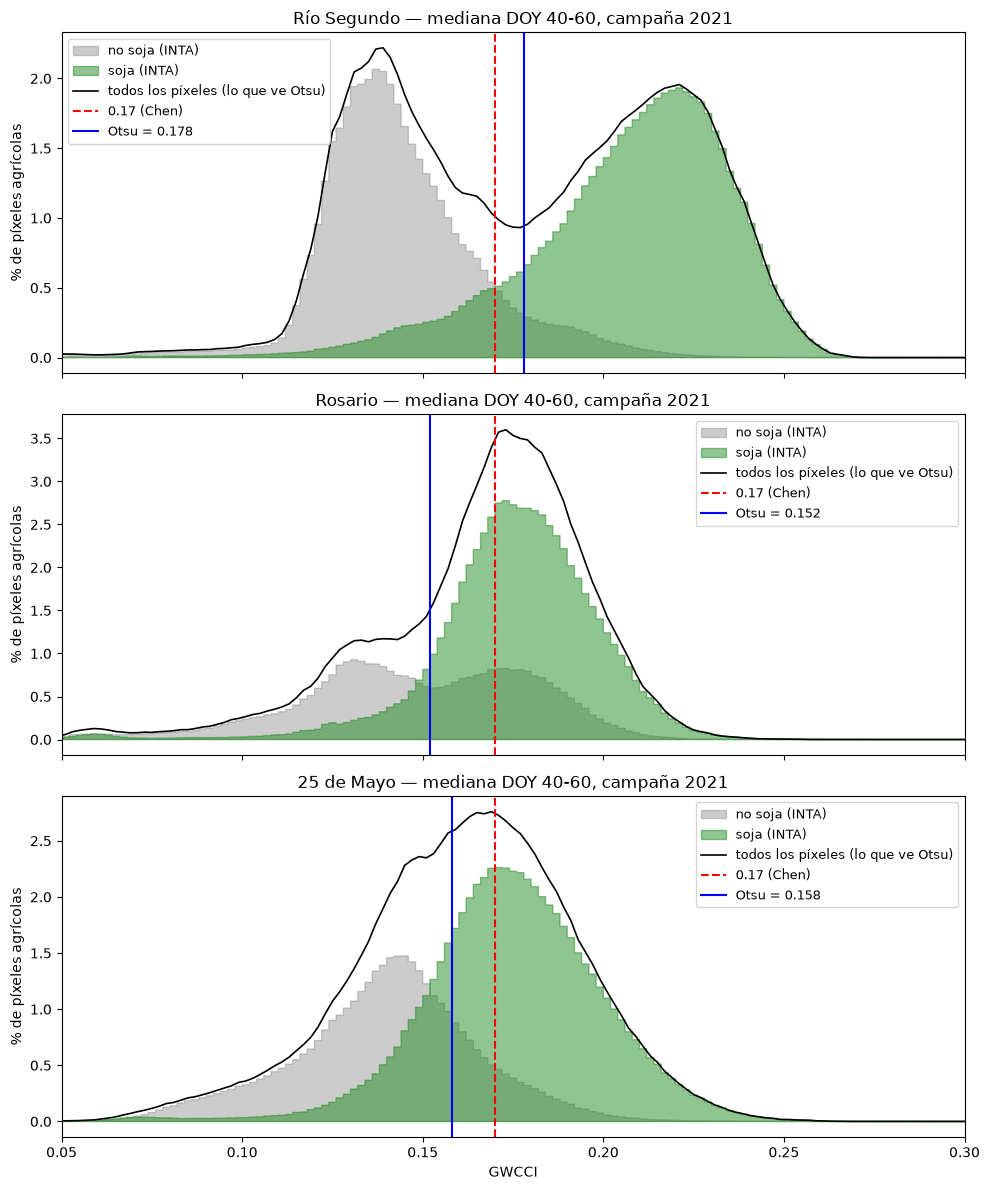

In [15]:
# --- 1. Error de área absoluto -------------------------------------------
ev["abs_err_area_otsu"] = ev["err_area_otsu"].abs()
print("Error de área absoluto medio (pp):")
print(ev.groupby("estrategia")[["abs_err_area", "abs_err_area_otsu"]].mean().reindex(orden).round(2).to_string())
print("\nDistribución del error de área con Otsu (pp, + = soja de más):")
print(ev.groupby("estrategia")["err_area_otsu"].describe()[["min", "25%", "50%", "75%", "max"]]
      .reindex(orden).round(1).to_string())

# --- 2. Casos extremos (ventana de Chen + Otsu) ---------------------------
c = ev[ev["estrategia"] == "Chen DOY 40-60"].copy()
c["soja_INTA_%"] = [100 * H[(l, "Chen DOY 40-60")][1][:, 1].sum() /
                    (H[(l, "Chen DOY 40-60")][0][:, 1].sum() + H[(l, "Chen DOY 40-60")][1][:, 1].sum())
                    for l in c["link"]]
c["otsu_menos_017"] = c["kappa_otsu"] - c["kappa_017"]
cols = ["link", "departamento", "provincia", "soja_INTA_%", "corte_otsu", "kappa_017", "kappa_otsu", "err_area_otsu"]
print(f"\nOtsu empeora el kappa en {(c['otsu_menos_017'] < 0).sum()} de {len(c)} departamentos.")
print("\nLos 8 cortes más bajos:")
print(c.sort_values("corte_otsu")[cols].head(8).round(3).to_string(index=False))
print("\nLos 8 donde Otsu más empeora:")
print(c.sort_values("otsu_menos_017")[cols].head(8).round(3).to_string(index=False))

# --- 3. Gráfico explicativo: 3 departamentos piloto ------------------------
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
for ax, (link, nombre) in zip(axes, [("14119", "Río Segundo"), ("82084", "Rosario"), ("06854", "25 de Mayo")]):
    h = H[(link, "Chen DOY 40-60")]
    x = h[0][:, 0] + (h[0][1, 0] - h[0][0, 0]) / 2
    total = h[0][:, 1].sum() + h[1][:, 1].sum()
    ax.fill_between(x, 100 * h[0][:, 1] / total, step="mid", alpha=0.4, color="0.5", label="no soja (INTA)")
    ax.fill_between(x, 100 * h[1][:, 1] / total, step="mid", alpha=0.5, color="forestgreen", label="soja (INTA)")
    ax.plot(x, 100 * (h[0][:, 1] + h[1][:, 1]) / total, color="black", lw=1.2,
            label="todos los píxeles (lo que ve Otsu)")
    corte = c.loc[c["link"] == link, "corte_otsu"].iloc[0]
    ax.axvline(UMBRAL, color="red", ls="--", label="0.17 (Chen)")
    ax.axvline(corte, color="blue", ls="-", label=f"Otsu = {corte:.3f}")
    ax.set_title(f"{nombre} — mediana DOY 40-60, campaña {CAMPANIA}", fontsize=12)
    ax.set_ylabel("% de píxeles agrícolas")
    ax.legend(fontsize=9)
axes[-1].set_xlim(0.05, 0.30)
axes[-1].set_xlabel("GWCCI")
fig.tight_layout()
fig.savefig(f"{FIG}/otsu_vs_017_piloto_{CAMPANIA}.png", dpi=150)
plt.show()

η y corte según si Otsu mejora o empeora:
mejora_otsu       False   True 
eta         min   0.597   0.569
            25%   0.677   0.632
            50%   0.715   0.656
            75%   0.742   0.692
            max   0.781   0.790
corte_otsu  min   0.116   0.120
            25%   0.137   0.146
            50%   0.150   0.154
            75%   0.170   0.160
            max   0.180   0.178
soja_INTA_% min  34.456  32.928
            25%  42.951  57.402
            50%  49.638  67.142
            75%  55.008  76.255
            max  66.812  86.682

Por provincia:
                eta  corte_otsu  otsu_menos_017
provincia                                      
Buenos Aires  0.645       0.152           0.161
Córdoba       0.724       0.169          -0.002
Entre Ríos    0.721       0.141           0.065
La Pampa      0.662       0.126           0.036
Santa Fe      0.706       0.159           0.064


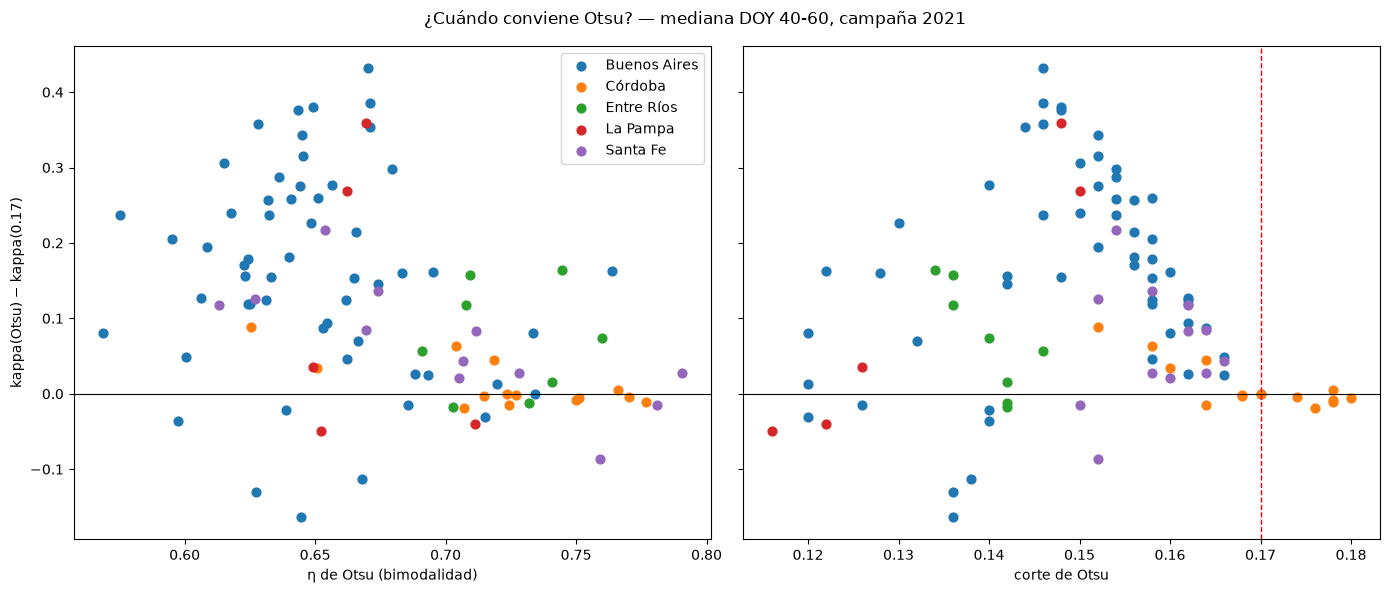

In [16]:
def eta_de(h):
    b, cnt = h[0][:, 0], h[0][:, 1] + h[1][:, 1]
    w = b[1] - b[0]; x = b + w / 2; p = cnt / cnt.sum()
    mu = (p * x).sum(); var_t = (p * (x - mu) ** 2).sum()
    w0, mu0 = p.cumsum(), (p * x).cumsum()
    with np.errstate(divide="ignore", invalid="ignore"):
        vb = (mu * w0 - mu0) ** 2 / (w0 * (1 - w0))
    return np.nanmax(np.where(np.isfinite(vb), vb, 0)) / var_t

c["eta"] = [eta_de(H[(l, "Chen DOY 40-60")]) for l in c["link"]]
c["mejora_otsu"] = c["otsu_menos_017"] > 0
print("η y corte según si Otsu mejora o empeora:")
print(c.groupby("mejora_otsu")[["eta", "corte_otsu", "soja_INTA_%"]].describe()
      .loc[:, (slice(None), ["min", "25%", "50%", "75%", "max"])].round(3).T.to_string())
print("\nPor provincia:")
print(c.groupby("provincia")[["eta", "corte_otsu", "otsu_menos_017"]].median().round(3).to_string())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for prov, g in c.groupby("provincia"):
    a1.scatter(g["eta"], g["otsu_menos_017"], label=prov, s=40)
    a2.scatter(g["corte_otsu"], g["otsu_menos_017"], label=prov, s=40)
for ax, xl in [(a1, "η de Otsu (bimodalidad)"), (a2, "corte de Otsu")]:
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel(xl)
a2.axvline(UMBRAL, color="red", ls="--", lw=1)
a1.set_ylabel("kappa(Otsu) − kappa(0.17)")
a1.legend()
fig.suptitle(f"¿Cuándo conviene Otsu? — mediana DOY 40-60, campaña {CAMPANIA}")
fig.tight_layout()
fig.savefig(f"{FIG}/otsu_cuando_conviene_{CAMPANIA}.png", dpi=150)
plt.show()

In [17]:
def kittler(bordes, c, pmin=0.05):
    """Umbral de mínimo error (Kittler & Illingworth, 1986) sobre un histograma."""
    w = bordes[1] - bordes[0]
    x = bordes + w / 2
    p = c / c.sum()
    P1, m1, s1 = p.cumsum(), (p * x).cumsum(), (p * x ** 2).cumsum()
    P2, m2, s2 = 1 - P1, (p * x).sum() - m1, (p * x ** 2).sum() - s1
    with np.errstate(all="ignore"):
        v1 = s1 / P1 - (m1 / P1) ** 2
        v2 = s2 / P2 - (m2 / P2) ** 2
        J = P1 * np.log(v1) + P2 * np.log(v2) - 2 * (P1 * np.log(P1) + P2 * np.log(P2))
    J[(P1 < pmin) | (P2 < pmin) | (v1 <= 0) | (v2 <= 0) | ~np.isfinite(J)] = np.inf
    return bordes[int(np.argmin(J))] + w

filas = []
for r in c.itertuples():
    h = H[(r.link, "Chen DOY 40-60")]
    b, todo = h[0][:, 0], h[0][:, 1] + h[1][:, 1]
    for metodo, u in [("0.17", UMBRAL), ("Otsu", r.corte_otsu), ("Kittler", kittler(b, todo))]:
        m = metricas(h, u)
        filas.append({"link": r.link, "departamento": r.departamento, "provincia": r.provincia,
                      "metodo": metodo, "umbral": u, "kappa": m["kappa"], "err_area": m["err_area"]})
um = pd.DataFrame(filas)
um["abs_err"] = um["err_area"].abs()
um.to_csv(f"{T}/umbrales_chen_{CAMPANIA}.csv", index=False)

print("Promedio general (mediana DOY 40-60):")
print(um.groupby("metodo")[["umbral", "kappa", "err_area", "abs_err"]].mean().round(3).to_string())
print("\nKappa por provincia:")
print(um.pivot_table(index="provincia", columns="metodo", values="kappa").round(3).to_string())
print("\nError de área absoluto por provincia (pp):")
print(um.pivot_table(index="provincia", columns="metodo", values="abs_err").round(1).to_string())

malos = c.loc[c["otsu_menos_017"] < -0.03, "link"]
print(f"\nDepartamentos donde Otsu empeoró más de 0.03 ({len(malos)}):")
print(um[um["link"].isin(malos)].pivot_table(index=["departamento", "provincia"], columns="metodo",
      values=["umbral", "kappa"]).round(3).to_string())

Promedio general (mediana DOY 40-60):
         umbral  kappa  err_area  abs_err
metodo                                   
0.17      0.170  0.431   -22.490   22.593
Kittler   0.120  0.298    20.938   25.156
Otsu      0.151  0.548    -0.142   11.884

Kappa por provincia:
metodo         0.17  Kittler   Otsu
provincia                          
Buenos Aires  0.343    0.204  0.504
Córdoba       0.716    0.502  0.728
Entre Ríos    0.403    0.402  0.473
La Pampa      0.248    0.095  0.362
Santa Fe      0.604    0.514  0.669

Error de área absoluto por provincia (pp):
metodo        0.17  Kittler  Otsu
provincia                        
Buenos Aires  30.1     28.1  13.2
Córdoba        5.3     20.8   5.0
Entre Ríos    11.3     25.5  19.5
La Pampa      35.9     33.8  16.8
Santa Fe       9.8     12.5   6.5

Departamentos donde Otsu empeoró más de 0.03 (8):
                                 kappa                umbral               
metodo                            0.17 Kittler   Otsu   0.17 Kittler 

In [6]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CAMPANIA, UMBRAL, COB_MIN = 2021, 0.17, 95
SEL_DESDE, SEL_HASTA = f"{CAMPANIA}-01-01", f"{CAMPANIA}-04-01"
T, FIG = "../results/tables", "../results/figures"

# --- Datos guardados -------------------------------------------------------
H = pickle.load(open(f"../data/processed/hist_gwcci_95deptos_{CAMPANIA}.pkl", "rb"))
df = pd.read_csv(f"{T}/serie_gcc_95deptos_{CAMPANIA}.csv", dtype={"link": str}, parse_dates=["fecha"])
df["cobertura"] = 100 * df["validos"] / df["total"]
sel = pd.read_csv(f"{T}/seleccion_imagen_{CAMPANIA}.csv", dtype={"link": str}, parse_dates=["fecha_sel"])
ev = pd.read_csv(f"{T}/evaluacion_estrategias_95deptos_{CAMPANIA}.csv", dtype={"link": str})

# --- Funciones -------------------------------------------------------------
def metricas(hs, u=UMBRAL):
    bordes, s, n = hs[1][:, 0], hs[1][:, 1], hs[0][:, 1]
    k = np.searchsorted(bordes, u - 1e-9)
    tp, fp, fn, tn = s[k:].sum(), n[k:].sum(), s[:k].sum(), n[:k].sum()
    N = tp + fp + fn + tn
    oa = (tp + tn) / N
    pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / N ** 2
    return {"kappa": (oa - pe) / (1 - pe), "OA": 100 * oa,
            "PA": 100 * tp / (tp + fn), "UA": 100 * tp / (tp + fp) if tp + fp else np.nan,
            "err_area": 100 * (fp - fn) / N}

def otsu(bordes, c):
    w = bordes[1] - bordes[0]
    x = bordes + w / 2
    p = c / c.sum()
    mu_t = (p * x).sum()
    w0, mu0 = p.cumsum(), (p * x).cumsum()
    with np.errstate(divide="ignore", invalid="ignore"):
        var_b = (mu_t * w0 - mu0) ** 2 / (w0 * (1 - w0))
    var_b[~np.isfinite(var_b)] = 0
    return bordes[int(np.argmax(var_b))] + w

# --- Tablas que usa el paso 47 --------------------------------------------
c = ev[ev["estrategia"] == "Chen DOY 40-60"].copy()
c["otsu_menos_017"] = c["kappa_otsu"] - c["kappa_017"]
malos = c.loc[c["otsu_menos_017"] < -0.03, "link"]

print(f"Histogramas: {len(H)} | serie: {len(df)} filas | selección: {len(sel)} | "
      f"Chen: {len(c)} deptos | Otsu falla en: {len(malos)}")

Histogramas: 907 | serie: 6697 filas | selección: 95 | Chen: 95 deptos | Otsu falla en: 8


In [7]:
# --- 1. Otsu con resguardo (exploratorio) ---------------------------------
c["kappa_resguardo"] = np.where(c["corte_otsu"] >= 0.14, c["kappa_otsu"], c["kappa_017"])
print("Kappa por provincia (mediana DOY 40-60):")
print(c.groupby("provincia")[["kappa_017", "kappa_otsu", "kappa_resguardo"]].mean().round(3).to_string())
print("Promedio:", c[["kappa_017", "kappa_otsu", "kappa_resguardo"]].mean().round(3).to_dict())

# --- 2. Departamentos problemáticos: Otsu en cada fecha candidata -----------
for l in malos:
    s = sel.set_index("link").loc[l]
    cand = df[(df["link"] == l) & (df["fecha"] >= SEL_DESDE) & (df["fecha"] < SEL_HASTA)
              & (df["cobertura"] >= COB_MIN)].sort_values("fecha")
    filas = []
    for r in cand.itertuples():
        h = H.get((l, f"{r.fecha:%Y-%m-%d} o{r.orbita}"))
        if h is None:
            continue
        corte = otsu(h[0][:, 0], h[0][:, 1] + h[1][:, 1])
        filas.append({"imagen": f"{r.fecha:%Y-%m-%d} o{r.orbita}", "gcc": round(r.gcc_agr, 3),
                      "corte_otsu": round(corte, 3), "kappa_017": round(metricas(h)["kappa"], 3),
                      "kappa_otsu": round(metricas(h, corte)["kappa"], 3)})
    print(f"\n=== {s['departamento']} ({s['provincia']}) — Chen+Otsu: "
          f"{c.loc[c['link'] == l, 'kappa_otsu'].iloc[0]:.3f} ===")
    print(pd.DataFrame(filas).to_string(index=False))

Kappa por provincia (mediana DOY 40-60):
              kappa_017  kappa_otsu  kappa_resguardo
provincia                                           
Buenos Aires      0.343       0.504            0.499
Córdoba           0.716       0.728            0.728
Entre Ríos        0.403       0.473            0.418
La Pampa          0.248       0.362            0.373
Santa Fe          0.604       0.669            0.669
Promedio: {'kappa_017': 0.431, 'kappa_otsu': 0.548, 'kappa_resguardo': 0.541}

=== Balcarce (Buenos Aires) — Chen+Otsu: 0.305 ===
         imagen   gcc  corte_otsu  kappa_017  kappa_otsu
2021-01-20 o124 0.409       0.126      0.088      -0.312
2021-01-25 o124 0.401       0.132      0.170      -0.265
2021-02-04 o124 0.405       0.132      0.227      -0.148
2021-02-24 o124 0.437       0.134      0.414       0.260
2021-03-06 o124 0.405       0.132      0.443       0.286
2021-03-31 o124 0.404       0.114      0.175       0.334

=== General Alvarado (Buenos Aires) — Chen+Otsu: 0.476 ===

In [11]:
import ee
import numpy as np

ee.Initialize(project="ee-mnolasco")
BASE, CAMPANIA, CS_UMBRAL, CRS = "users/mnolasco/FORMAR_2024_2026", 2021, 0.60, "EPSG:32720"

deptos = ee.FeatureCollection(f"{BASE}/departments_selected").select(["link"])
agricola = ee.Image(f"{BASE}/AgriLand-2019").eq(1).selfMask()
ref = ee.Image(f"{BASE}/MNC_verano-{CAMPANIA}").eq(11)
cs = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")

def preparar(i):
    r = (i.select(["B4", "B8", "B11"]).divide(10000).toFloat()
         .updateMask(i.select("cs_cdf").gte(CS_UMBRAL)))
    ndvi = r.normalizedDifference(["B8", "B4"]).rename("NDVI")
    doy = (ee.Image.constant(ee.Date(i.get("system:time_start")).getRelative("day", "year").add(1))
           .toFloat().rename("doy").updateMask(ndvi.mask()))
    return r.addBands([ndvi, doy])

RED = (ee.Reducer.fixedHistogram(-0.1, 0.5, 300).forEach(["s", "n"])
       .combine(ee.Reducer.median().forEach(["doy"])))
claves_s = ee.List.sequence(0, 299).map(lambda k: ee.String("s").cat(ee.Number(k).format("%03d")))
claves_n = ee.List.sequence(0, 299).map(lambda k: ee.String("n").cat(ee.Number(k).format("%03d")))

def aplanar(f):
    cs_ = ee.Array(f.get("s")).slice(1, 1, 2).project([0]).toList()
    cn_ = ee.Array(f.get("n")).slice(1, 1, 2).project([0]).toList()
    d = ee.Dictionary.fromLists(claves_s, cs_).combine(ee.Dictionary.fromLists(claves_n, cn_))
    return ee.Feature(f.geometry().centroid(100), d).set({"link": f.get("link"), "doy_mediano": f.get("doy")})


def histos_maxndvi(fc):
    """Mosaico de máximo NDVI (ene–mar) sobre fc, GWCCI e histogramas por clase INTA."""
    col = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
           .filterBounds(fc).filterDate(f"{CAMPANIA}-01-01", f"{CAMPANIA}-04-01")
           .linkCollection(cs, ["cs_cdf"]).map(preparar))
    mos = col.qualityMosaic("NDVI")
    g = mos.select("NDVI").multiply(mos.select("B11"))
    img = ee.Image.cat(g.updateMask(ref.eq(1)).rename("s"),
                       g.updateMask(ref.eq(0)).rename("n"),
                       mos.select("doy")).updateMask(agricola)
    return img.reduceRegions(fc, RED, scale=30, crs=CRS, tileScale=8).map(aplanar)

# --- prueba: solo Rosario ----------------------------------------------------
p = histos_maxndvi(deptos.filter(ee.Filter.eq("link", "82084"))).first().getInfo()["properties"]
s = np.array([p[f"s{k:03d}"] for k in range(300)])
n = np.array([p[f"n{k:03d}"] for k in range(300)])
bordes = -0.1 + 0.002 * np.arange(300)
H_r = {1: np.column_stack([bordes, s]), 0: np.column_stack([bordes, n])}
print("Día del año mediano de los píxeles elegidos:", p["doy_mediano"])
print(f"Píxeles soja: {s.sum():.0f} | no soja: {n.sum():.0f} | columnas: {len(p)}")
print("Kappa con 0.17 (Rosario, mosaico máx. NDVI):", round(metricas(H_r)["kappa"], 3))

Día del año mediano de los píxeles elegidos: 36.00000000000001
Píxeles soja: 758024 | no soja: 403482 | columnas: 602
Kappa con 0.17 (Rosario, mosaico máx. NDVI): 0.418


In [12]:
prueba = ee.batch.Export.table.toAsset(
    collection=histos_maxndvi(deptos.filter(ee.Filter.eq("link", "82084"))),
    description=f"prueba_maxndvi_{CAMPANIA}",
    assetId=f"{BASE}/prueba_hist_maxndvi_{CAMPANIA}")
prueba.start()
print("Prueba lanzada:", prueba.status()["state"])

Prueba lanzada: READY


In [13]:
t = ee.FeatureCollection(f"{BASE}/prueba_hist_maxndvi_{CAMPANIA}")
print("Filas:", t.size().getInfo())
p = t.first().getInfo()["properties"]
print("Columnas:", len(p), "| doy_mediano:", p["doy_mediano"])
print("Píxeles soja:", sum(p[f"s{k:03d}"] for k in range(300)),
      "| no soja:", sum(p[f"n{k:03d}"] for k in range(300)))

Filas: 1
Columnas: 602 | doy_mediano: 36.00000000000001
Píxeles soja: 758023.5490196077 | no soja: 403482.1058823529


In [14]:
tarea = ee.batch.Export.table.toAsset(
    collection=histos_maxndvi(deptos),
    description=f"hist_maxndvi_{CAMPANIA}",
    assetId=f"{BASE}/hist_gwcci_maxndvi_{CAMPANIA}")
tarea.start()
print("Tarea lanzada:", tarea.status()["state"])

Tarea lanzada: READY


In [15]:
import ee
ee.Initialize(project="ee-mnolasco")
BASE = "users/mnolasco/FORMAR_2024_2026"

# --- 1. Leer y verificar -----------------------------------------------------
feats = ee.FeatureCollection(f"{BASE}/hist_gwcci_maxndvi_{CAMPANIA}").getInfo()["features"]
bordes = -0.1 + 0.002 * np.arange(300)
HM, doy = {}, {}
for f in feats:
    p = f["properties"]
    l = str(p["link"]).zfill(5)
    s = np.array([p[f"s{k:03d}"] for k in range(300)])
    n = np.array([p[f"n{k:03d}"] for k in range(300)])
    HM[l] = {1: np.column_stack([bordes, s]), 0: np.column_stack([bordes, n])}
    doy[l] = p.get("doy_mediano")

tot = lambda h: h[0][:, 1].sum() + h[1][:, 1].sum()
ratio = pd.Series({l: tot(HM[l]) / tot(H[(l, "Chen DOY 40-60")]) for l in HM})
print(f"Filas: {len(HM)} | píxeles mosaico / píxeles Chen: mediana {ratio.median():.3f}, "
      f"mín {ratio.min():.3f}, máx {ratio.max():.3f}")

info = sel.set_index("link")[["departamento", "provincia"]]
d = pd.Series(doy).rename("doy_mediano").to_frame().join(info)
print("\nDía del año mediano de los píxeles del mosaico, por provincia:")
print(d.groupby("provincia")["doy_mediano"].describe()[["min", "50%", "max"]].round(0).to_string())

# --- 2. Evaluar --------------------------------------------------------------
filas = []
for l, h in HM.items():
    corte = otsu(h[0][:, 0], h[0][:, 1] + h[1][:, 1])
    m17, mo = metricas(h), metricas(h, corte)
    filas.append({"link": l, "provincia": info.loc[l, "provincia"], "estrategia": "máx NDVI",
                  "kappa_017": m17["kappa"], "kappa_otsu": mo["kappa"],
                  "err_area_017": m17["err_area"], "err_area_otsu": mo["err_area"], "corte_otsu": corte})
mx = pd.DataFrame(filas)
mx.to_csv(f"{T}/evaluacion_maxndvi_{CAMPANIA}.csv", index=False)

cols = ["link", "provincia", "estrategia", "kappa_017", "kappa_otsu", "err_area_017", "err_area_otsu", "corte_otsu"]
todo = pd.concat([ev[cols], mx[cols]], ignore_index=True)
todo["abs_017"], todo["abs_otsu"] = todo["err_area_017"].abs(), todo["err_area_otsu"].abs()
orden2 = ["mediana feb", "Chen DOY 40-60", "regla 2 pasos", "máx NDVI", "techo"]

print("\nPromedio de 95 departamentos:")
print(todo.groupby("estrategia")[["kappa_017", "kappa_otsu", "err_area_017", "err_area_otsu",
                                  "abs_017", "abs_otsu", "corte_otsu"]].mean().reindex(orden2).round(3).to_string())
print("\nKappa con 0.17 por provincia:")
print(todo.pivot_table(index="provincia", columns="estrategia", values="kappa_017")[orden2].round(3).to_string())
print("\nKappa con Otsu por provincia:")
print(todo.pivot_table(index="provincia", columns="estrategia", values="kappa_otsu")[orden2].round(3).to_string())

from scipy.stats import wilcoxon
k = todo.pivot_table(index="link", columns="estrategia", values=["kappa_017", "kappa_otsu"])
for umb in ["kappa_017", "kappa_otsu"]:
    dif = k[(umb, "máx NDVI")] - k[(umb, "Chen DOY 40-60")]
    print(f"\nMáx NDVI vs Chen ({umb}): mejora en {(dif > 0).sum()} de {len(dif)}; "
          f"diferencia media {dif.mean():+.3f}; Wilcoxon p = {wilcoxon(dif).pvalue:.2g}")

Filas: 95 | píxeles mosaico / píxeles Chen: mediana 1.000, mín 1.000, máx 1.126

Día del año mediano de los píxeles del mosaico, por provincia:
               min   50%   max
provincia                     
Buenos Aires  35.0  48.0  55.0
Córdoba       36.0  49.0  59.0
Entre Ríos    36.0  46.0  48.0
La Pampa      49.0  49.0  54.0
Santa Fe      36.0  41.0  49.0

Promedio de 95 departamentos:
                kappa_017  kappa_otsu  err_area_017  err_area_otsu  abs_017  abs_otsu  corte_otsu
estrategia                                                                                       
mediana feb         0.465       0.546       -19.560         -2.017   19.761    12.039       0.155
Chen DOY 40-60      0.431       0.548       -22.490         -0.142   22.593    11.884       0.151
regla 2 pasos       0.492       0.509       -17.185         -3.468   17.618    13.671       0.157
máx NDVI            0.438       0.447       -15.070         -8.557   15.868    13.884       0.166
techo               

In [16]:
import ee
ee.Initialize(project="ee-mnolasco")
BASE, CRS = "users/mnolasco/FORMAR_2024_2026", "EPSG:32720"
CAMPANIAS = range(2019, 2026)
EXT = [10, 11, 12, 15, 16, 18]       # maíz, soja, girasol, algodón, maní, sorgo

deptos = ee.FeatureCollection(f"{BASE}/departments_selected").select(["link"])
agri = ee.Image(f"{BASE}/AgriLand-2019").eq(1).unmask(0)

bandas = [agri.rename("agri19")]
for y in CAMPANIAS:
    m = ee.Image(f"{BASE}/MNC_verano-{y}")
    ext = m.remap(EXT, [1] * len(EXT), 0).unmask(0)
    soja = m.eq(11).unmask(0)
    bandas += [ext.rename(f"ext{y}"), ext.And(agri).rename(f"ext_en_agri{y}"),
               soja.rename(f"soja{y}"), soja.And(agri.Not()).rename(f"soja_fuera{y}")]
img = ee.Image.cat(bandas).multiply(ee.Image.pixelArea().divide(1e4))     # hectáreas

def areas(fc):
    return (img.reduceRegions(fc, ee.Reducer.sum(), scale=30, crs=CRS, tileScale=8)
            .map(lambda f: f.setGeometry(f.geometry().centroid(100))))

# --- prueba: Rosario ------------------------------------------------------------
p = areas(deptos.filter(ee.Filter.eq("link", "82084"))).first().getInfo()["properties"]
print(f"AgriLand-2019: {p['agri19']:,.0f} ha")
for y in CAMPANIAS:
    print(f"{y}: extensiva {p[f'ext{y}']:,.0f} ha | dentro de la máscara {100 * p[f'ext_en_agri{y}'] / p[f'ext{y}']:.1f} % "
          f"| soja {p[f'soja{y}']:,.0f} ha, fuera de la máscara {100 * p[f'soja_fuera{y}'] / p[f'soja{y}']:.1f} %")

AgriLand-2019: 106,155 ha
2019: extensiva 106,155 ha | dentro de la máscara 100.0 % | soja 89,825 ha, fuera de la máscara 0.0 %
2020: extensiva 105,067 ha | dentro de la máscara 93.0 % | soja 87,990 ha, fuera de la máscara 6.1 %
2021: extensiva 107,321 ha | dentro de la máscara 91.2 % | soja 74,479 ha, fuera de la máscara 8.4 %
2022: extensiva 98,426 ha | dentro de la máscara 92.8 % | soja 69,271 ha, fuera de la máscara 5.8 %
2023: extensiva 92,068 ha | dentro de la máscara 93.6 % | soja 61,885 ha, fuera de la máscara 5.5 %
2024: extensiva 97,610 ha | dentro de la máscara 93.6 % | soja 70,494 ha, fuera de la máscara 5.4 %
2025: extensiva 99,988 ha | dentro de la máscara 92.9 % | soja 91,726 ha, fuera de la máscara 6.5 %


In [17]:
tarea = ee.batch.Export.table.toAsset(
    collection=areas(deptos),
    description="areas_agricolas_inta_2019_2025",
    assetId=f"{BASE}/areas_agricolas_inta_2019_2025")
tarea.start()
print("Tarea lanzada:", tarea.status()["state"])

Tarea lanzada: READY


In [18]:
import ee
import pandas as pd
ee.Initialize(project="ee-mnolasco")
BASE = "users/mnolasco/FORMAR_2024_2026"

feats = ee.FeatureCollection(f"{BASE}/areas_agricolas_inta_2019_2025").getInfo()["features"]
info = pd.read_csv("../results/tables/seleccion_imagen_2021.csv", dtype={"link": str})[["link", "departamento", "provincia"]]

filas = []
for f in feats:
    p = f["properties"]
    for y in range(2019, 2026):
        filas.append({"link": str(p["link"]).zfill(5), "campania": y, "agri19": p["agri19"],
                      "ext": p[f"ext{y}"], "ext_en_agri": p[f"ext_en_agri{y}"],
                      "soja": p[f"soja{y}"], "soja_fuera": p[f"soja_fuera{y}"]})
ar = pd.DataFrame(filas).merge(info, on="link", how="left")
ar.to_csv("../results/tables/areas_agricolas_inta_2019_2025.csv", index=False)

def indicadores(g):
    s = g[["agri19", "ext", "ext_en_agri", "soja", "soja_fuera"]].sum()
    return pd.Series({"ext_dentro_%": 100 * s["ext_en_agri"] / s["ext"],
                      "soja_fuera_%": 100 * s["soja_fuera"] / s["soja"],
                      "mascara_no_ext_%": 100 * (1 - s["ext_en_agri"] / s["agri19"]),
                      "ext_Mha": s["ext"] / 1e6, "soja_Mha": s["soja"] / 1e6})

print(f"Departamentos: {ar['link'].nunique()}  (2019 es el control: debe dar 100 % / 0 %)\n")
print("1. Total de los 95 departamentos, por campaña:")
print(ar.groupby("campania").apply(indicadores).round(2).to_string())

post = ar[ar["campania"] > 2019]
print("\n2. Soja fuera de la máscara (%), por provincia y campaña:")
print(post.groupby(["provincia", "campania"]).apply(indicadores)["soja_fuera_%"]
      .unstack().round(1).to_string())

print("\n3. Máscara que no fue agrícola extensiva ese año (%), por provincia y campaña:")
print(post.groupby(["provincia", "campania"]).apply(indicadores)["mascara_no_ext_%"]
      .unstack().round(1).to_string())

d = post.groupby(["link", "departamento", "provincia"]).apply(indicadores)
print("\n4. Los 10 departamentos con más soja fuera de la máscara (promedio 2020–2025):")
print(d.sort_values("soja_fuera_%", ascending=False).head(10)[["soja_fuera_%", "ext_dentro_%",
      "mascara_no_ext_%"]].round(1).to_string())

Departamentos: 95  (2019 es el control: debe dar 100 % / 0 %)

1. Total de los 95 departamentos, por campaña:
          ext_dentro_%  soja_fuera_%  mascara_no_ext_%  ext_Mha  soja_Mha
campania                                                                 
2019            100.00          0.00              0.46    16.62     10.87
2020             76.66         21.20             11.41    19.29     12.83
2021             73.65         24.47              9.60    20.49     13.01
2022             74.06         20.64             13.97    19.39     10.69
2023             77.82         20.76             19.34    17.30     10.86
2024             72.13         24.80             13.28    20.07     11.63
2025             72.46         25.24             13.47    19.94     13.74

2. Soja fuera de la máscara (%), por provincia y campaña:
campania      2020  2021  2022  2023  2024  2025
provincia                                       
Buenos Aires  33.3  37.6  32.5  31.8  38.3  38.0
Córdoba        6.5